<a href="https://colab.research.google.com/github/Priya-DharshiniRamesh/24ADI006_DEEP-LEARNING/blob/main/DL_EXP_7A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**DEEP LEARNING -24ADI006**

**EXPT NO: 7	 IMPLEMENTATION OF A SIMPLE AUTOENCODER FOR DIMENSIONALITY REDUCTION AND FEATURE LEARNING**


**Name: Priya Dharshini R**

**Roll no: 24BAD092**

**AIM**

To implement and train a simple Autoencoder for dimensionality reduction and feature learning by compressing input data into a lower-dimensional representation and reconstructing the original data from the learned features


**SOFTWARE REQUIREMENTS**

•	Python

•	TensorFlow / Keras / PyTorch

•	Google Colab

•	GitHub

•	NumPy

•	Matplotlib

•	Pandas

•	Scikit-learn



**OBJECTIVES**

**Students will be able to:**

•	Understand the architecture and working of an Autoencoder.

•	Identify the functions of the Encoder, bottleneck, and Decoder.

•	Prepare and normalize input data for Autoencoder training.

•	Build and train an Autoencoder using a suitable dataset.

•	Perform dimensionality reduction through latent-space representations.

•	Evaluate reconstruction performance using suitable loss metrics.

•	Visualize reconstructed data and analyze the learned features.

•	Document the experiment and manage the notebook using GitHub.



**PART A: DATASET PREPARATION**

**Perform the following tasks:**

•	Load a suitable dataset, such as the MNIST handwritten digits dataset.

•	Explore the dataset and examine sample input images.

•	Identify the dimensions and data types of the input samples.

•	Normalize the pixel values to a suitable range, such as 0 to 1.

•	Reshape the input images into one-dimensional vectors if using a Dense Autoencoder.

•	Split the dataset into training and testing datasets.

•	Use the input data as both the input and target output for reconstruction.

•	Display a sample of the original images.


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training shape: (60000, 28, 28) dtype: uint8
Testing shape: (10000, 28, 28) dtype: uint8
Original pixel range: 0 to 255
Normalized training data: (60000, 784)
Normalized testing data: (10000, 784)
Normalized pixel range: 0.0 to 1.0
Autoencoder targets are identical to the inputs.


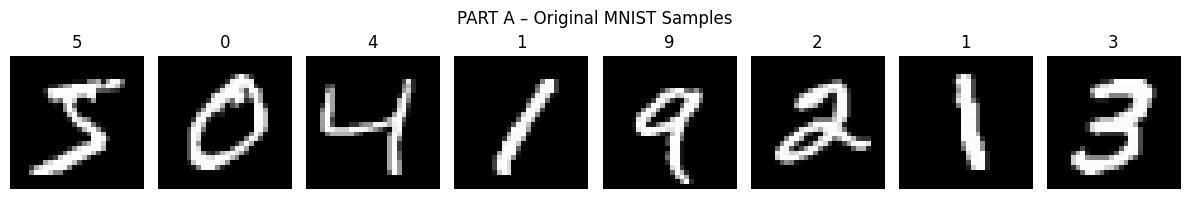

Priya Dharshini R (24BAD092)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.decomposition import PCA

np.random.seed(42)
tf.random.set_seed(42)

# Load MNIST dataset
(x_train_img, y_train), (x_test_img, y_test) = tf.keras.datasets.mnist.load_data()

print("Training shape:", x_train_img.shape, "dtype:", x_train_img.dtype)
print("Testing shape:", x_test_img.shape, "dtype:", x_test_img.dtype)
print("Original pixel range:", x_train_img.min(), "to", x_train_img.max())

# Normalize and reshape the images
x_train = x_train_img.astype("float32").reshape(-1, 784) / 255.0
x_test = x_test_img.astype("float32").reshape(-1, 784) / 255.0

print("Normalized training data:", x_train.shape)
print("Normalized testing data:", x_test.shape)
print("Normalized pixel range:", x_train.min(), "to", x_train.max())
print("Autoencoder targets are identical to the inputs.")

# Display original images
fig, axes = plt.subplots(1, 8, figsize=(12, 2))

for i, ax in enumerate(axes):
    ax.imshow(x_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(str(y_train[i]))
    ax.axis("off")

plt.suptitle("PART A – Original MNIST Samples")
plt.tight_layout()
plt.show()

print("Priya Dharshini R (24BAD092)")

**PART B: IMPLEMENTING THE AUTOENCODER MODEL**

**Perform the following tasks:**

•	Define the input layer based on the dimensions of the dataset.

•	Create an Encoder using one or more Dense layers.

•	Introduce a bottleneck layer with fewer neurons than the input layer to learn a compact representation.

•	Create a Decoder to reconstruct the input from the bottleneck representation.

•	Use a suitable activation function, such as ReLU for hidden layers and Sigmoid for normalized image reconstruction.

•	Combine the Encoder and Decoder to construct the complete Autoencoder.

•	Compile the model using an appropriate optimizer, such as Adam, and a reconstruction loss function, such as Mean Squared Error (MSE).

•	Display the model architecture and model summary.


In [2]:
# Encoder
input_layer = layers.Input(shape=(784,), name="image_input")

h = layers.Dense(128, activation="relu", name="encoder_dense_1")(input_layer)
h = layers.Dense(64, activation="relu", name="encoder_dense_2")(h)

latent = layers.Dense(32, activation="relu", name="bottleneck")(h)

encoder = Model(input_layer, latent, name="encoder")

# Decoder
latent_input = layers.Input(shape=(32,), name="latent_input")

d = layers.Dense(64, activation="relu", name="decoder_dense_1")(latent_input)
d = layers.Dense(128, activation="relu", name="decoder_dense_2")(d)

reconstruction = layers.Dense(784, activation="sigmoid", name="reconstructed_image")(d)

decoder = Model(latent_input, reconstruction, name="decoder")

# Complete Autoencoder
autoencoder = Model(
    input_layer,
    decoder(encoder(input_layer)),
    name="mnist_autoencoder"
)

# Compile model
autoencoder.compile(optimizer="adam", loss="mse")

# Display model summaries
print("Encoder summary:")
encoder.summary()

print("Decoder summary:")
decoder.summary()

print("Complete Autoencoder summary:")
autoencoder.summary()

print("Model structure: 784 -> 128 -> 64 -> 32 -> 64 -> 128 -> 784")

print("Priya Dharshini R (24BAD092)")

Encoder summary:


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_1 (Dense)         │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_2 (Dense)         │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

Model structure: 784 -> 128 -> 64 -> 32 -> 64 -> 128 -> 784
Priya Dharshini R (24BAD092)


**PART C: MODEL TRAINING AND PERFORMANCE EVALUATION**

**Perform the following tasks:**

•	Train the Autoencoder using the prepared training dataset.

•	Use the original input samples as target outputs.

•	Validate the model using validation data or the testing dataset, as appropriate.

•**Record:**

o	Training loss

o	Validation loss

•	Evaluate the trained model using the test dataset.

•	Calculate the reconstruction Mean Squared Error (MSE).

•	Plot the training and validation loss against the number of epochs.

•	Compare the original input images with their reconstructed outputs.


Epoch 1/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 0.0672 - val_loss: 0.0389
Epoch 2/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 0.0320 - val_loss: 0.0267
Epoch 3/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - loss: 0.0242 - val_loss: 0.0222
Epoch 4/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step - loss: 0.0212 - val_loss: 0.0200
Epoch 5/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - loss: 0.0194 - val_loss: 0.0185
Epoch 6/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - loss: 0.0180 - val_loss: 0.0172
Epoch 7/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0168 - val_loss: 0.0161
Epoch 8/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0160 - val_loss: 0.0154
Epoch 9/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 0.0154 - val_loss: 0.0150
Epoch 10/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0149 - val_loss: 0.0146
Final training loss (MSE): 0.014909
Final validation loss (MSE): 0.014638
Test reconstruction MSE (Keras): 0.014325
Test reconstr

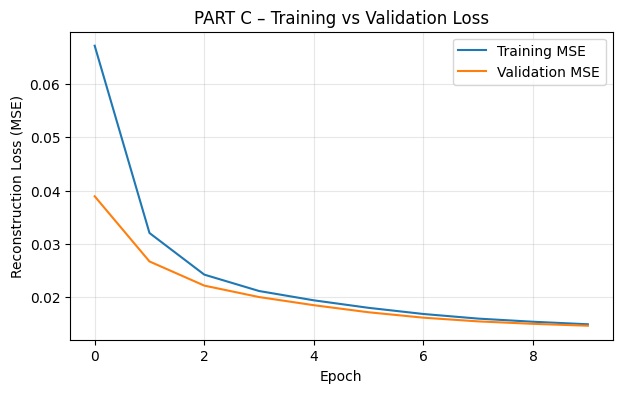

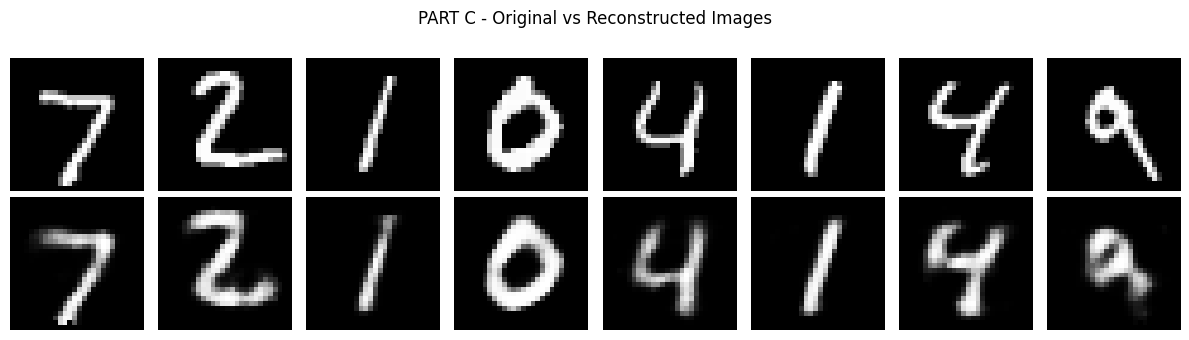

Priya Dharshini R (24BAD092)


In [3]:
# Train the Autoencoder
history = autoencoder.fit(
    x_train, x_train,
    epochs=10,
    batch_size=256,
    validation_split=0.1,
    shuffle=True,
    verbose=1
)

# Evaluate the model
test_mse = autoencoder.evaluate(x_test, x_test, verbose=0)

# Reconstruct test images
x_reconstructed = autoencoder.predict(
    x_test,
    batch_size=256,
    verbose=0
)

# Calculate reconstruction MSE
manual_mse = np.mean((x_test - x_reconstructed) ** 2)

print(f"Final training loss (MSE): {history.history['loss'][-1]:.6f}")
print(f"Final validation loss (MSE): {history.history['val_loss'][-1]:.6f}")
print(f"Test reconstruction MSE (Keras): {test_mse:.6f}")
print(f"Test reconstruction MSE (NumPy): {manual_mse:.6f}")

# Plot training and validation loss
plt.figure(figsize=(7, 4))

plt.plot(history.history["loss"], label="Training MSE")
plt.plot(history.history["val_loss"], label="Validation MSE")

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Loss (MSE)")
plt.title("PART C – Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Compare original and reconstructed images
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))

for i in range(8):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[1, i].imshow(x_reconstructed[i].reshape(28, 28), cmap="gray")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", rotation=90)
axes[1, 0].set_ylabel("Reconstructed", rotation=90)

plt.suptitle("PART C - Original vs Reconstructed Images")
plt.tight_layout()
plt.show()

print("Priya Dharshini R (24BAD092)")

**PART D: DIMENSIONALITY REDUCTION, FEATURE VISUALIZATION AND EXPERIMENT MANAGEMENT**

**Perform the following tasks:**

•	Extract latent-space representations of test samples using the trained Encoder.

•	Compare the dimensions of the original input data and compressed representations.

•	Visualize the latent representations using a suitable plot.

•	Reconstruct selected test samples using the Decoder and compare them with the original images.

•	Record observations on dimensionality reduction and reconstruction quality.

•	Document the observations and upload the notebook to GitHub.



Original test shape: (10000, 784)
Learned latent shape: (10000, 32)
Features per image: 784 -> 32
Dimensionality reduction: 95.92%


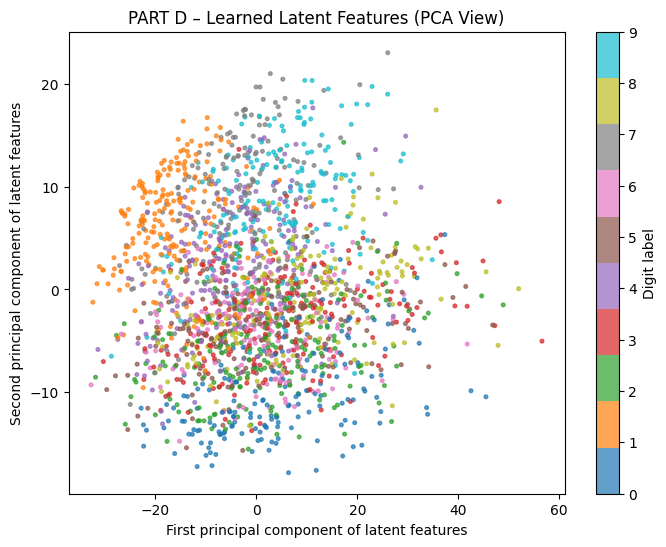

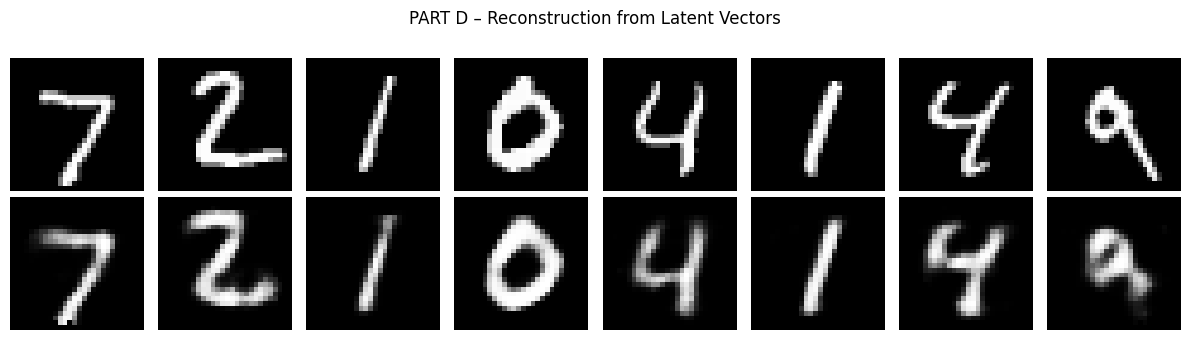

,Metric,Value
0,Original features,784.000000
1,Latent features,32.000000
2,Reduction (%),95.920000
3,Test reconstruction MSE,0.014325


Priya Dharshini R (24BAD092)


In [4]:
# Extract latent-space representations
latent_test = encoder.predict(
    x_test,
    batch_size=256,
    verbose=0
)

print("Original test shape:", x_test.shape)
print("Learned latent shape:", latent_test.shape)
print("Features per image: 784 -> 32")

reduction = (1 - 32 / 784) * 100

print(f"Dimensionality reduction: {reduction:.2f}%")

# Visualize latent features using PCA
visualization_count = 2000

latent_2d = PCA(
    n_components=2,
    random_state=42
).fit_transform(latent_test[:visualization_count])

plt.figure(figsize=(8, 6))

points = plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=y_test[:visualization_count],
    cmap="tab10",
    s=7,
    alpha=0.7
)

plt.colorbar(points, ticks=range(10), label="Digit label")
plt.xlabel("First principal component of latent features")
plt.ylabel("Second principal component of latent features")
plt.title("PART D – Learned Latent Features (PCA View)")
plt.show()

# Reconstruct selected test samples using Decoder
selected = np.array([0, 1, 2, 3, 4, 5, 6, 7])

decoded_selected = decoder.predict(
    latent_test[selected],
    verbose=0
)

fig, axes = plt.subplots(2, len(selected), figsize=(12, 3.5))

for col, idx in enumerate(selected):
    axes[0, col].imshow(x_test[idx].reshape(28, 28), cmap="gray")
    axes[1, col].imshow(decoded_selected[col].reshape(28, 28), cmap="gray")

    axes[0, col].axis("off")
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Decoded")

plt.suptitle("PART D – Reconstruction from Latent Vectors")
plt.tight_layout()
plt.show()

# Display observations
observations = pd.DataFrame({
    "Metric": [
        "Original features",
        "Latent features",
        "Reduction (%)",
        "Test reconstruction MSE"
    ],
    "Value": [
        784,
        32,
        round(reduction, 2),
        round(float(manual_mse), 6)
    ]
})

display(observations)

print("Priya Dharshini R (24BAD092)")

**OBSERVATIONS:**
- The Autoencoder compressed 784 input features into 32 latent features.

- It achieved 95.92% dimensionality reduction.

- The Decoder successfully reconstructed images from compressed representations.

- The low reconstruction error indicates good reconstruction performance.